# Cryptocurrency Data Analysis (EDA)
## Dataset: `coingecko_data4.csv`

**Goal:** Clean the supplied dataset, explore individual variables, examine relationships, perform a small multivariate analysis, and test a small number of meaningful hypotheses.

**Libraries:** Pandas, NumPy, Matplotlib, Seaborn, SciPy

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

## 2. Load and inspect the data

In [2]:
df = pd.read_csv("coingecko_data4.csv")

In [3]:
df.shape

(3000, 9)

In [4]:
df.columns.tolist()

['Rank',
 'Name',
 'Buy',
 'Price',
 '1h %',
 '24h %',
 '7d %',
 'Market Cap',
 'Circulating Supply']

In [5]:
df.head()

,Rank,Name,Buy,Price,1h %,24h %,7d %,Market Cap,Circulating Supply
0,1,Bitcoin BTC,Buy,"$81,280.89",0.6%,3.1%,2.2%,"$41,441,960,779","$1,633,736,485,222"
1,2,Ethereum ETH,Buy,"$2,372.42",0.7%,5.9%,8.0%,"$18,921,242,787","$289,740,969,837"
2,3,Tether USDT,NaN,$0.9991,0.0%,0.0%,0.0%,"$72,465,083,704","$183,876,315,874"
3,4,BNB BNB,Buy,$719.06,0.4%,3.5%,6.6%,"$942,036,953","$95,751,544,591"
4,5,XRP XRP,Buy,$1.31,0.2%,4.3%,6.7%,"$2,332,257,331","$82,531,684,555"


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Rank                3000 non-null   int64 
 1   Name                3000 non-null   object
 2   Buy                 2430 non-null   object
 3   Price               3000 non-null   object
 4   1h %                3000 non-null   object
 5   24h %               3000 non-null   object
 6   7d %                3000 non-null   object
 7   Market Cap          3000 non-null   object
 8   Circulating Supply  3000 non-null   object
dtypes: int64(1), object(8)
memory usage: 211.1+ KB


In [7]:
df.isna().sum()

Rank                    0
Name                    0
Buy                   570
Price                   0
1h %                    0
24h %                   0
7d %                    0
Market Cap              0
Circulating Supply      0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(1934)

In [9]:
df = df.drop_duplicates()

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1066 entries, 0 to 2799
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Rank                1066 non-null   int64 
 1   Name                1066 non-null   object
 2   Buy                 861 non-null    object
 3   Price               1066 non-null   object
 4   1h %                1066 non-null   object
 5   24h %               1066 non-null   object
 6   7d %                1066 non-null   object
 7   Market Cap          1066 non-null   object
 8   Circulating Supply  1066 non-null   object
dtypes: int64(1), object(8)
memory usage: 83.3+ KB


## 3. Data cleaning

### What the initial inspection shows
- The file has 100 rows and 9 columns.
- `Buy` has missing values. It is a website button/action field, not a market measurement, so it is not useful for this EDA and will be removed rather than deleting 19 otherwise usable assets.
- Price, percentage-change, and monetary columns are stored as text because they contain `$`, commas, and `%` symbols. We will convert them to numeric values.
- **Column-label check:** In the supplied file, the values in `Market Cap` look like 24-hour trading-volume amounts (for example, Bitcoin is about $27.3 billion), while `Circulating Supply` contains values that look like market capitalizations (Bitcoin is about $1.67 trillion). We will rename these two fields to `Volume_24h_USD` and `Market_Cap_USD` based on their value patterns. Please verify these labels against the original webpage/source before submitting the project; if the source page says otherwise, correct the mapping.
- The original `Rank` values skip some numbers. This is not a missing-value problem in the rows we have and does not need to be filled in.

We will keep the useful records and handle missing values based on their meaning instead of dropping rows unnecessarily.

In [11]:
data = df.copy()

if "Buy" in data.columns:                         # Remove the non-analytical website action column.
    data = data.drop(columns=["Buy"])

In [12]:
def to_number(series):                                 # Convert currency strings such as "$83,296.52" to numbers.
    return pd.to_numeric(
        series.astype(str).str.replace("$", "", regex=False)
                     .str.replace(",", "", regex=False)
                     .str.strip(),
        errors="coerce"
    )

if "Price" in data.columns:
    data["Price_USD"] = to_number(data["Price"])
    data = data.drop(columns=["Price"])


In [13]:
# Convert percentage strings such as "0.4%" to numeric percentage points (0.4).
for col in ["1h %", "24h %", "7d %"]:
    if col in data.columns:
        data[col] = pd.to_numeric(
            data[col].astype(str).str.replace("%", "", regex=False).str.strip(),
            errors="coerce"
        )


In [14]:
# Rename the two fields after checking the values in this specific file.
rename_map = {
    "Market Cap": "Volume_24h_USD",
    "Circulating Supply": "Market_Cap_USD"
}
data = data.rename(columns=rename_map)

In [15]:
# Ensure monetary fields are numeric.
for col in ["Volume_24h_USD", "Market_Cap_USD"]:
    if col in data.columns:
        data[col] = to_number(data[col])

In [16]:
# Standardize cryptocurrency names and numeric rank.
if "Name" in data.columns:
    data["Name"] = data["Name"].astype("string").str.strip()

if "Rank" in data.columns:
    data["Rank"] = pd.to_numeric(data["Rank"], errors="coerce")


In [17]:
data.shape

(1066, 8)

In [18]:
data.dtypes

Rank                       int64
Name              string[python]
1h %                     float64
24h %                    float64
7d %                     float64
Volume_24h_USD           float64
Market_Cap_USD             int64
Price_USD                float64
dtype: object

In [19]:
data.head()

,Rank,Name,1h %,24h %,7d %,Volume_24h_USD,Market_Cap_USD,Price_USD
0,1,Bitcoin BTC,0.6,3.1,2.2,4.144196e+10,1633736485222,81280.8900
1,2,Ethereum ETH,0.7,5.9,8.0,1.892124e+10,289740969837,2372.4200
2,3,Tether USDT,0.0,0.0,0.0,7.246508e+10,183876315874,0.9991
3,4,BNB BNB,0.4,3.5,6.6,9.420370e+08,95751544591,719.0600
4,5,XRP XRP,0.2,4.3,6.7,2.332257e+09,82531684555,1.3100


In [20]:
data.describe()

,Rank,1h %,24h %,7d %,Volume_24h_USD,Market_Cap_USD,Price_USD
count,1066.000000,1066.000000,1066.000000,1066.000000,1.066000e+03,1.066000e+03,1066.000000
mean,49.878049,0.634615,4.702439,7.197561,1.968480e+09,3.194033e+10,1148.286997
std,29.112799,0.676190,4.081774,7.317784,9.007584e+09,1.825523e+11,8944.947466
min,1.000000,0.000000,0.000000,0.000000,0.000000e+00,6.464666e+08,0.004282
25%,24.000000,0.100000,1.300000,1.200000,2.437039e+07,9.972981e+08,0.184600
50%,50.000000,0.500000,4.700000,6.800000,1.012173e+08,1.881406e+09,0.999700
75%,75.000000,0.900000,6.500000,10.500000,2.985234e+08,4.533708e+09,7.130000
max,100.000000,5.200000,24.300000,47.300000,7.285208e+10,1.637465e+12,81472.160000


In [21]:
data["Name"].nunique()

100

In [22]:
data["Name"].duplicated().sum()

np.int64(966)

In [23]:
data["Rank"].min(), data["Rank"].max()

(1, 100)

## 4. Univariate analysis
Univariate analysis studies one variable at a time. We will focus on price, 24-hour change, 7-day change, market capitalization, and 24-hour volume.

Because money values are highly skewed, histograms of raw price/market values can be hard to read. We use a log scale for those charts; the underlying data is not changed.

### 4.1 Distribution of percentage changes

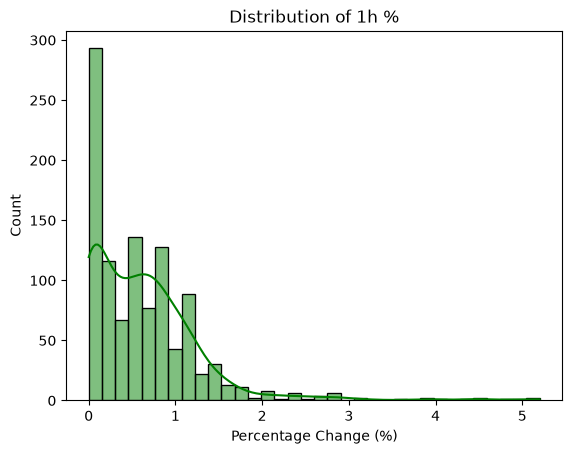

In [24]:
sns.histplot(data["1h %"], kde=True,color="green")
plt.title("Distribution of 1h %")
plt.xlabel("Percentage Change (%)")
plt.show()

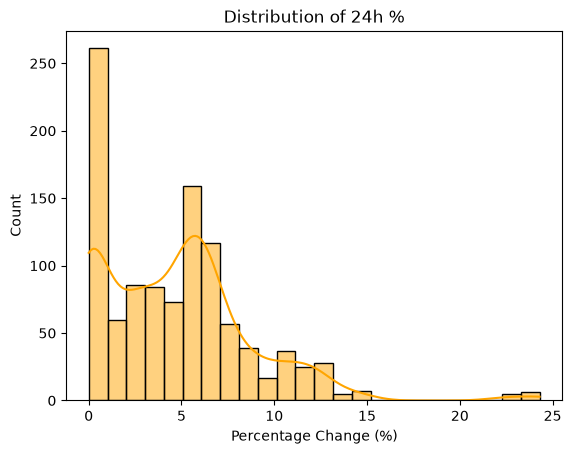

In [25]:
sns.histplot(data["24h %"], kde=True,color="orange")
plt.title("Distribution of 24h %")
plt.xlabel("Percentage Change (%)")
plt.show()

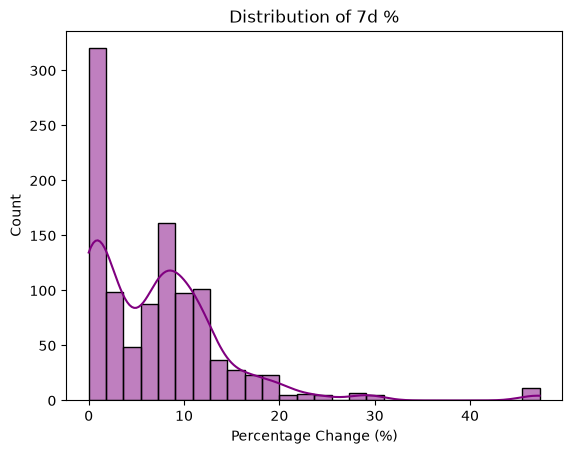

In [26]:
sns.histplot(data["7d %"], kde=True,color="purple")
plt.title("Distribution of 7d %")
plt.xlabel("Percentage Change (%)")
plt.show()

### 4.2 Price distribution
This chart uses a logarithmic x-axis because asset prices range widely. A log axis helps display low- and high-priced assets together.

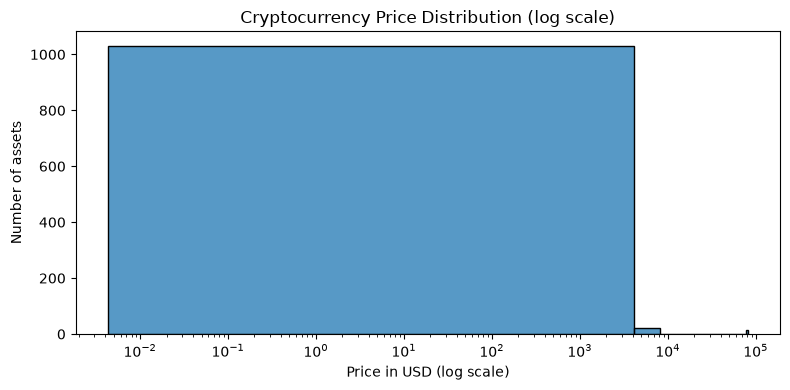

In [27]:
positive_prices = data.loc[data["Price_USD"] > 0, "Price_USD"]

plt.figure(figsize=(8, 4))
sns.histplot(positive_prices, bins=20)
plt.xscale("log")
plt.title("Cryptocurrency Price Distribution (log scale)")
plt.xlabel("Price in USD (log scale)")
plt.ylabel("Number of assets")
plt.tight_layout()
plt.show()

### 4.3 Largest market capitalizations
This is a ranked comparison, so a horizontal bar chart is easier to read than a pie chart.

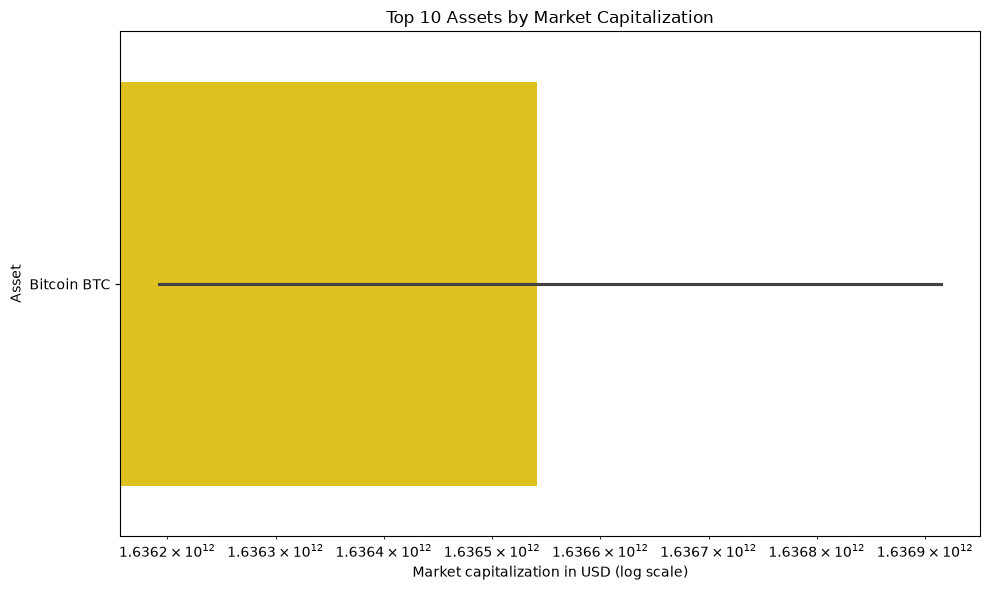

In [28]:
top_market_cap = data.nlargest(10, "Market_Cap_USD").sort_values("Market_Cap_USD")

plt.figure(figsize=(10, 6))
sns.barplot(data=top_market_cap, x="Market_Cap_USD", y="Name",color="gold")
plt.xscale("log")
plt.title("Top 10 Assets by Market Capitalization")
plt.xlabel("Market capitalization in USD (log scale)")
plt.ylabel("Asset")
plt.tight_layout()
plt.show()

In [29]:
display(data.nlargest(10, "Market_Cap_USD")[["Rank", "Name", "Market_Cap_USD"]])

,Rank,Name,Market_Cap_USD
1900,1,Bitcoin BTC,1637464616845
2100,1,Bitcoin BTC,1637246281481
1200,1,Bitcoin BTC,1636849418491
900,1,Bitcoin BTC,1636816318193
1600,1,Bitcoin BTC,1636733066440
1300,1,Bitcoin BTC,1636468891924
1400,1,Bitcoin BTC,1636323722775
600,1,Bitcoin BTC,1636100139575
400,1,Bitcoin BTC,1635856774112
2400,1,Bitcoin BTC,1635556293405


### 4.4 Summary of 24-hour movement
This table summarizes how many assets rose, fell, or showed no change according to the values in this file.

In [30]:
change_24h = data["24h %"]

movement_summary = pd.Series({
    "Positive change": int((change_24h > 0).sum()),
    "Negative change": int((change_24h < 0).sum()),
    "No change": int((change_24h == 0).sum())
}, name="Number of assets")

display(movement_summary.to_frame())

,Number of assets
Positive change,887
Negative change,0
No change,179


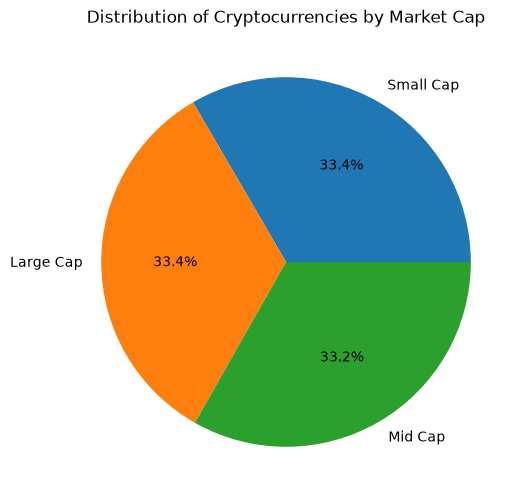

In [31]:
data["Category"] = pd.qcut(
    data["Market_Cap_USD"],
    q=3,
    labels=["Small Cap", "Mid Cap", "Large Cap"]
)

category_counts = data["Category"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(
    category_counts,
    labels=category_counts.index,
    autopct="%1.1f%%"
)
plt.title("Distribution of Cryptocurrencies by Market Cap")
plt.show()

In [32]:
data.columns

Index(['Rank', 'Name', '1h %', '24h %', '7d %', 'Volume_24h_USD',
       'Market_Cap_USD', 'Price_USD', 'Category'],
      dtype='object')

## 5. Bivariate analysis
Bivariate analysis studies the relationship between two variables. We will examine two questions:
1. Are short-term (24-hour) changes associated with 7-day changes?
2. Do assets with larger market capitalization also tend to have higher 24-hour trading volume?

Scatterplots and Spearman correlation are appropriate for these questions because cryptocurrency values can be skewed and relationships may not be linear.

### 5.1 24-hour change versus 7-day change

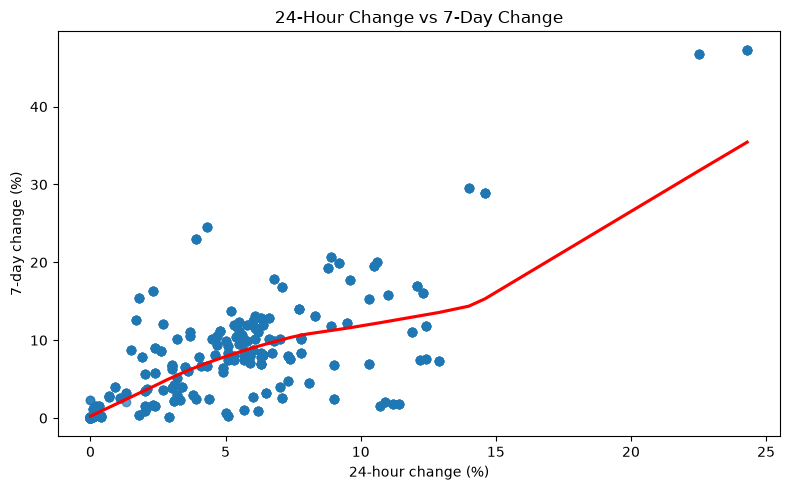

Spearman correlation: 0.724
p-value: 1.41705e-173


In [33]:
plt.figure(figsize=(8, 5))
sns.regplot(
    data=data, x="24h %", y="7d %",
    scatter_kws={"alpha": 0.7}, lowess=True,
    line_kws={"color": "red"}
)
plt.title("24-Hour Change vs 7-Day Change")
plt.xlabel("24-hour change (%)")
plt.ylabel("7-day change (%)")
plt.tight_layout()
plt.show()

rho, p_value = spearmanr(data["24h %"], data["7d %"])
print(f"Spearman correlation: {rho:.3f}")
print(f"p-value: {p_value:.6g}")

**Interpretation guide:** Spearman's correlation ranges from -1 to +1. A positive value means higher 24-hour changes tend to accompany higher 7-day changes in this dataset. The p-value assesses evidence against the hypothesis of no monotonic association, under the test's assumptions; it does not establish causation.

### 5.2 Market capitalization versus 24-hour volume
Both variables are heavily skewed, so use logarithmic axes.

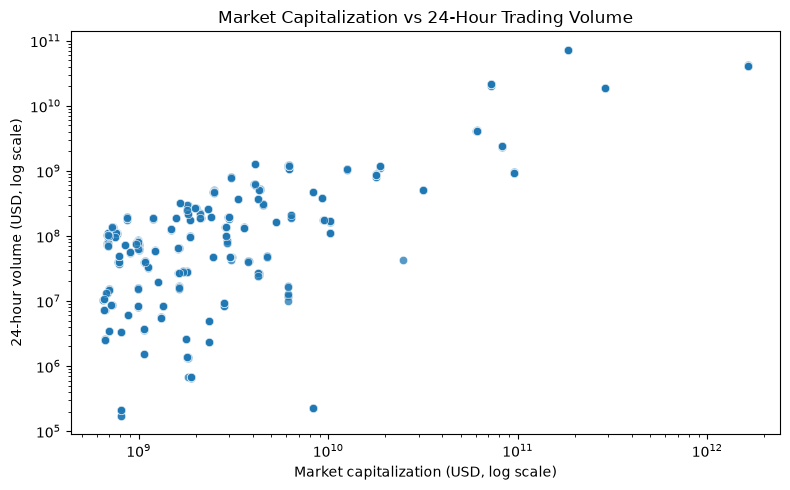

Spearman correlation: 0.638
p-value: 1.74365e-121


In [34]:
plot_data = data[
    (data["Market_Cap_USD"] > 0) &
    (data["Volume_24h_USD"] > 0)
].copy()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=plot_data,
    x="Market_Cap_USD", y="Volume_24h_USD",
    alpha=0.75
)
plt.xscale("log")
plt.yscale("log")
plt.title("Market Capitalization vs 24-Hour Trading Volume")
plt.xlabel("Market capitalization (USD, log scale)")
plt.ylabel("24-hour volume (USD, log scale)")
plt.tight_layout()
plt.show()

rho_mv, p_mv = spearmanr(
    plot_data["Market_Cap_USD"],
    plot_data["Volume_24h_USD"]
)
print(f"Spearman correlation: {rho_mv:.3f}")
print(f"p-value: {p_mv:.6g}")

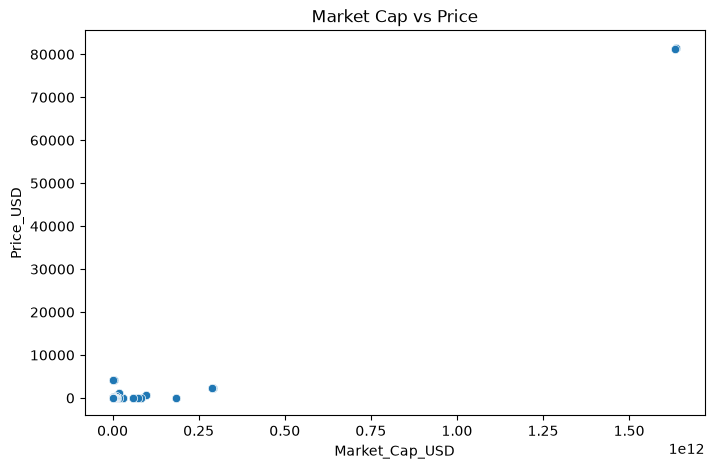

In [35]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=data,
                x="Market_Cap_USD",
                y="Price_USD")

plt.title("Market Cap vs Price")
plt.show()

In [36]:
data.columns

Index(['Rank', 'Name', '1h %', '24h %', '7d %', 'Volume_24h_USD',
       'Market_Cap_USD', 'Price_USD', 'Category'],
      dtype='object')

## 6. Multivariate analysis
Here we examine several numeric variables together. We will use a correlation heatmap. For market cap and volume, we use log-transformed versions because their ranges are extremely wide. Log transformation is used for visualization/relationship analysis only; the original values remain available.

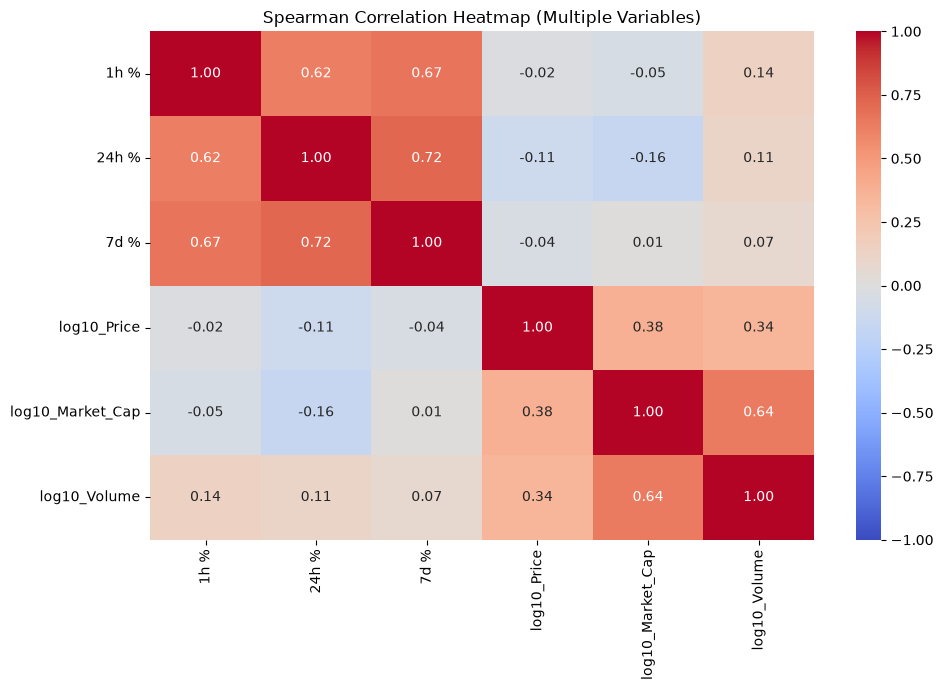

In [37]:
multi = data[[
    "1h %", "24h %", "7d %",
    "Price_USD", "Market_Cap_USD", "Volume_24h_USD"
]].copy()

multi["log10_Market_Cap"] = np.log10(multi["Market_Cap_USD"].where(multi["Market_Cap_USD"] > 0))
multi["log10_Volume"] = np.log10(multi["Volume_24h_USD"].where(multi["Volume_24h_USD"] > 0))
multi["log10_Price"] = np.log10(multi["Price_USD"].where(multi["Price_USD"] > 0))

corr_columns = [
    "1h %", "24h %", "7d %",
    "log10_Price", "log10_Market_Cap", "log10_Volume"
]
corr_matrix = multi[corr_columns].corr(method="spearman")

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.title("Spearman Correlation Heatmap (Multiple Variables)")
plt.tight_layout()
plt.show()

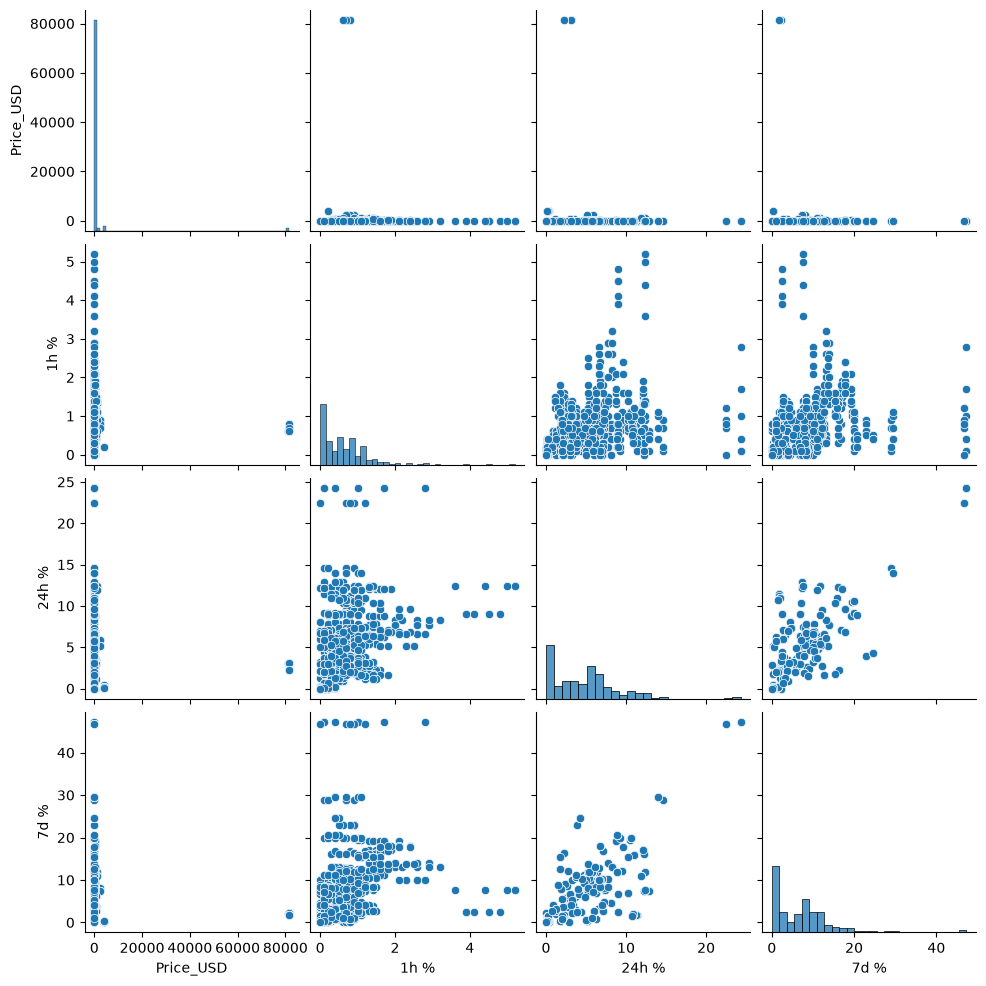

In [38]:
sns.pairplot(
    data[["Price_USD", "1h %", "24h %", "7d %"]]
)
plt.show()

## 7. Hypothesis testing
We will test only the two relationships that were already motivated by the bivariate analysis. Spearman correlation is used because it measures monotonic association and is less sensitive to extreme magnitudes than Pearson correlation.

### Hypothesis 1: 24-hour change and 7-day change
- **H₀ (null):** There is no monotonic association between 24-hour and 7-day percentage changes.
- **H₁ (alternative):** There is a monotonic association between 24-hour and 7-day percentage changes.

Use a 5% significance level (`alpha = 0.05`). The test is two-sided.

In [39]:
import scipy
from scipy import stats

corr, p_val = stats.pearsonr(data['24h %'], data['7d %'])

print('corr_value:', corr)
print('p_value:', p_val)
print('--------------------------------')

if p_val < 0.05:
    print('reject h0: significant correlation')
else:
    print('fail to reject h0: no significant correlation')

corr_value: 0.7481881091767322
p_value: 8.780015711348561e-192
--------------------------------
reject h0: significant correlation


### Hypothesis 2: Market capitalization and 24-hour volume
- **H₀ (null):** There is no monotonic association between market capitalization and 24-hour volume.
- **H₁ (alternative):** There is a monotonic association between market capitalization and 24-hour volume.

Only positive values are included here because the plot and interpretation use logarithmic scales.

In [40]:
corr, p_val = stats.pearsonr(data['Market_Cap_USD'], data['Volume_24h_USD'])

print('corr_value:', corr)
print('p_value:', p_val)
print('--------------------------------')

if p_val < 0.05:
    print('reject h0: significant correlation')
else:
    print('fail to reject h0: no significant correlation')

corr_value: 0.6045421351428379
p_value: 3.2385513761497043e-107
--------------------------------
reject h0: significant correlation


#### Hypothesis 3:One-Way ANOVA testing

In [41]:
from scipy import stats
import pandas as pd
import numpy as np

# Prepare data
anova_data = data[["Category", "24h %"]].dropna()

# Separate the three groups
small_cap = anova_data.loc[
    anova_data["Category"] == "Small Cap", "24h %"
]

mid_cap = anova_data.loc[
    anova_data["Category"] == "Mid Cap", "24h %"
]

large_cap = anova_data.loc[
    anova_data["Category"] == "Large Cap", "24h %"
]

# Display group means
print("Mean 24-hour percentage change:")
print(anova_data.groupby("Category", observed=True)["24h %"].mean())

# Perform One-Way ANOVA
f_stat, p_value = stats.f_oneway(
    small_cap,
    mid_cap,
    large_cap
)

print("\nANOVA Results")
print("-------------------------")
print("F-statistic:", f_stat)
print("P-value:", p_value)

# Decision
alpha = 0.05

if p_value < alpha:
    print("\nReject H0")
    print("There is a significant difference in mean 24-hour changes among the categories.")
else:
    print("\nFail to reject H0")
    print("There is no statistically significant difference in mean 24-hour changes among the categories.")


Mean 24-hour percentage change:
Category
Small Cap    5.381180
Mid Cap      4.522034
Large Cap    4.203090
Name: 24h %, dtype: float64

ANOVA Results
-------------------------
F-statistic: 8.036413580004522
P-value: 0.00034352081375707035

Reject H0
There is a significant difference in mean 24-hour changes among the categories.


## 8. Save the cleaned dataset

In [61]:
cleaned_file = "coingecko_data_clean1.csv"
data.to_csv(cleaned_file, index=False)
print(f"Saved cleaned dataset as: {cleaned_file}")

Saved cleaned dataset as: coingecko_data_clean1.csv


## 9. Final findings and conclusion
Run the notebook first, then complete these findings using the actual printed results.

1. **Data quality:** State the number of rows and columns retained after cleaning, and whether any missing core values remained.
2. **Univariate findings:** Report the median 24-hour and 7-day changes, and identify the highest market-cap assets.
3. **Bivariate findings:** Describe the direction and strength of the Spearman correlations.
4. **Multivariate findings:** Mention the strongest relationships visible in the correlation heatmap.
5. **Hypothesis testing:** For each test, report the correlation coefficient, p-value, and decision at `alpha = 0.05`.
6. **Limitations:** The asset list is a snapshot, selected by rank, and the column mapping should be checked against the original website.
